# 01 · Qual busca encontra as teses certas?

Antes de gerar respostas, a busca precisa trazer os documentos certos: se ela falha, o LLM
responde com base nos trabalhos errados. Aqui comparamos as três buscas de `src/busca.py`:

- **semântica**: pelo sentido (embeddings);
- **BM25**: pelas palavras;
- **híbrida**: as duas combinadas pela Reciprocal Rank Fusion.

**Como medir.** O script `src/gerar_perguntas.py` sorteou 60 trabalhos (4 por ano) e pediu ao
Gemini a pergunta que cada um responde, sem copiar o título. Para cada pergunta, sabemos qual
trabalho a originou, e vemos em que posição ele aparece em cada busca.

- **Recall@k**: fração das perguntas em que o trabalho aparece entre os k primeiros resultados.
  Recall@5 importa mais, porque é mais ou menos quantos documentos o LLM vai ler.
- **MRR** (*mean reciprocal rank*): a média de 1/posição. Vale 1 se o trabalho vem sempre em
  1º lugar, 0,5 se vem sempre em 2º, e 0 se fica fora dos 10 primeiros.

In [4]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Os scripts usam caminhos a partir da raiz do repositório, então o notebook roda de lá
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.append("src")
from busca import MODOS, Buscador

FIGURAS = Path("reports/figures")
RELATORIOS = Path("reports")
FIGURAS.mkdir(parents=True, exist_ok=True)

TINTA = "#52514e"
CORES = {"semantica": "#2a78d6", "bm25": "#eb6834", "hibrida": "#1baf7a"}
NOMES = {"semantica": "Semântica", "bm25": "BM25", "hibrida": "Híbrida"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA, "xtick.color": TINTA,
    "ytick.color": TINTA, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e8e7e3", "font.size": 10,
})

with open("data/perguntas_avaliacao.jsonl", encoding="utf-8") as arquivo:
    perguntas = pd.DataFrame([json.loads(linha) for linha in arquivo]).drop_duplicates("id", keep="last")

buscador = Buscador()
print(f"{len(perguntas)} perguntas de teste; {len(buscador.documentos)} trabalhos no índice")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

60 perguntas de teste; 23007 trabalhos no índice


## Algumas perguntas de teste

In [5]:
pd.set_option("display.max_colwidth", 110)
perguntas[["pergunta", "titulo"]].head(6)

,pergunta,titulo
0,Como estudos empíricos podem avaliar a adequação dos processos de especificação de requisitos aos modelos ...,Um experimento na engenharia de requisitos para caracterização do processo e sua adequação as práticas esp...
1,Como incorporar ontologias difusas e contexto para enriquecer semanticamente regras de associação e padrõe...,"""Tarefas de Mineração de Dados com Aplicação de Contexto: Estudo de Caso na Meta Referencial Médica"""
2,Como lógicas modais podem ser aplicadas na verificação de propriedades topológicas de grafos e em sistemas...,APLICAÇÕES DE LÓGICA MODAIS A TEORIA DE GRAFOS E SISTEMAS CONCORRENTES
3,Quais técnicas utilizam casamento de grafos e relações espaciais para resolver o problema de correspondênc...,Duas abordagens para casamento de padrões de pontos usando relações espaciais e casamento entre grafos
4,Como determinar limites teóricos para parâmetros de coloração gulosa e b-coloração em produtos de grafos?,Parâmetros de Coloração de Vértices Baseados em Algoritmos de Coloração
5,Como extrair título e texto de notícias na web eficientemente sem depender da renderização completa das pá...,Efficient methods for information extraction in news webpages.


## Resultados

Para cada pergunta e cada busca, guardamos a posição do trabalho certo entre os 10 primeiros, 
ou "fora", se não aparecer.

In [6]:
posicao_no_indice = {id_: i for i, id_ in enumerate(buscador.documentos["id"])}

linhas = []
for item in perguntas.itertuples():
    alvo = posicao_no_indice[item.id]
    for modo in MODOS:
        ranking = buscador.ranking(item.pergunta, modo, k=10)
        posicao = ranking.index(alvo) + 1 if alvo in ranking else None
        linhas.append({"id": item.id, "modo": modo, "posicao": posicao})
posicoes = pd.DataFrame(linhas)

def metricas(grupo):
    p = grupo["posicao"]
    return pd.Series({
        "acerto em 1º": (p == 1).mean(),
        "recall@5": (p <= 5).mean(),
        "recall@10": p.notna().mean(),
        "MRR": (1 / p).fillna(0).mean(),
    })

resultados = posicoes.groupby("modo").apply(metricas, include_groups=False).loc[list(MODOS)]
resultados.index = resultados.index.map(NOMES)
resultados.to_csv(RELATORIOS / "avaliacao_busca.csv", float_format="%.3f")
resultados.style.format("{:.2f}")

,acerto em 1º,recall@5,recall@10,MRR
modo,,,,
Semântica,0.20,0.30,0.37,0.25
BM25,0.60,0.73,0.75,0.66
Híbrida,0.30,0.55,0.67,0.41


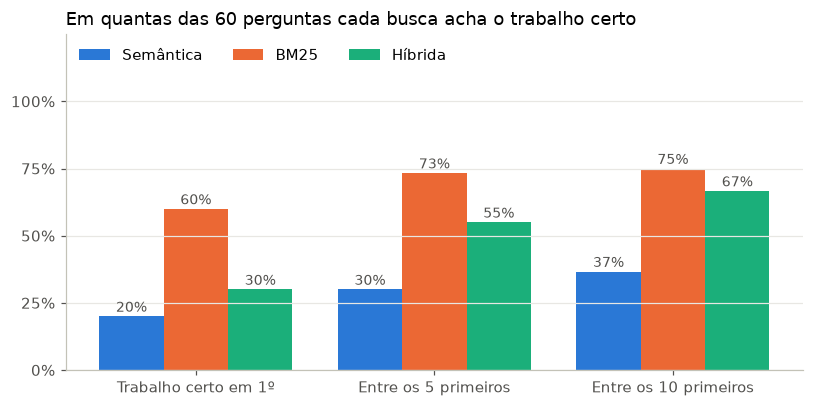

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
medidas = ["acerto em 1º", "recall@5", "recall@10"]
x = np.arange(len(medidas))
largura = 0.27
for i, modo in enumerate(MODOS):
    valores = resultados.loc[NOMES[modo], medidas] * 100
    deslocamento = (i - 1) * largura
    ax.bar(x + deslocamento, valores, width=largura, color=CORES[modo], label=NOMES[modo])
    for j, valor in enumerate(valores):
        ax.annotate(f"{valor:.0f}%", (j + deslocamento, valor), xytext=(0, 3),
                    textcoords="offset points", ha="center", color=TINTA, fontsize=9)
ax.set_xticks(x, ["Trabalho certo em 1º", "Entre os 5 primeiros", "Entre os 10 primeiros"])
ax.set_ylim(0, 125)  # espaço para a legenda acima das barras
ax.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.legend(frameon=False, loc="upper left", ncol=3)
ax.set_title(f"Em quantas das {len(perguntas)} perguntas cada busca acha o trabalho certo",
             loc="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURAS / "avaliacao_busca.png", bbox_inches="tight")

## Onde as buscas discordam

As perguntas em que uma busca acha o trabalho entre os 5 primeiros e a outra não mostram o que
cada uma faz melhor.

In [8]:
tabela = posicoes.pivot(index="id", columns="modo", values="posicao")
achou = tabela <= 5
so_bm25 = tabela[achou["bm25"] & ~achou["semantica"]].index
so_semantica = tabela[achou["semantica"] & ~achou["bm25"]].index
print(f"Só o BM25 acha: {len(so_bm25)} perguntas | só a semântica acha: {len(so_semantica)} perguntas")

colunas = ["pergunta", "titulo"]
print("\nExemplos em que só o BM25 acha:")
display(perguntas.set_index("id").loc[so_bm25[:4], colunas])
print("Exemplos em que só a semântica acha:")
display(perguntas.set_index("id").loc[so_semantica[:4], colunas])

Só o BM25 acha: 29 perguntas | só a semântica acha: 3 perguntas

Exemplos em que só o BM25 acha:


,pergunta,titulo
id,,
713,Como incorporar ontologias difusas e contexto para enriquecer semanticamente regras de associação e padrõe...,"""Tarefas de Mineração de Dados com Aplicação de Contexto: Estudo de Caso na Meta Referencial Médica"""
744,Quais técnicas utilizam casamento de grafos e relações espaciais para resolver o problema de correspondênc...,Duas abordagens para casamento de padrões de pontos usando relações espaciais e casamento entre grafos
1202,Como determinar limites teóricos para parâmetros de coloração gulosa e b-coloração em produtos de grafos?,Parâmetros de Coloração de Vértices Baseados em Algoritmos de Coloração
2338,Como apoiar a aplicação de controle estatístico de processos de desenvolvimento de software em ambientes i...,Apoio ao Controle Estatístico de Processos de Software Integrado a um ADS


Exemplos em que só a semântica acha:


,pergunta,titulo
id,,
4070,Quais técnicas permitem converter automaticamente gravações esportivas bidimensionais em vídeos estereoscó...,CONVERSÃO DE VÍDEO 2D PARA 3D EM FILMAGENS PANORÂMICAS DE FUTEBOL
15014,Como integrar sistemas multiagentes e cadeias de blocos privadas para gerenciar o armazenamento anônimo de...,ON THE USE OF BLOCKCHAIN STRUCTURES IN A MULTIAGENT BASED SOFTWARE ENGINEERING METHOD: A HEALTHCARE EXAMPLE
21695,Como identificar e selecionar fatias relevantes em exames tridimensionais de imagem médica utilizando mapa...,ABORDAGEM DE APRENDIZADO PROFUNDO PARA EXTRAÇÃO DE QUADROS SIGNIFICATIVOS EM VOLUMES DE TOMOGRAFIA COMPUTA...


## Um exemplo lado a lado

A pergunta do primeiro teste do índice, que a busca semântica respondeu com trabalhos sobre
redes neurais em geral, sem nenhum sobre câncer.

In [9]:
exemplo = "redes neurais para diagnóstico de câncer"
lado_a_lado = pd.DataFrame({
    NOMES[modo]: buscador.buscar(exemplo, modo, k=5)["titulo"].str[:70].str.capitalize().to_list()
    for modo in MODOS
}, index=range(1, 6))
lado_a_lado

,Semântica,BM25,Híbrida
1,Interpretable deep neural networks with rejection option on tabular da,"Utilização de redes neurais convolucionais, descritores calculados e i",Detecção e classificação da alta expressão da proteína e-caderina no c
2,Arquitetura federated learning e redes cnn na classificação de doenças,Um metodo automatico de deteccao de massas em mamografias por meio de,Automated segmentation of tumor regions from oral histological whole s
3,Processamento de fotomicrografias de fígados de ratos por morfologia m,Modelo computacional para classificação de nódulos pulmonares utilizan,Cnn-based methods and datasets for segmentation and counting of nuclei
4,Sincronização por acoplamento de osciladores e a sua aplicação em apre,Diagnóstico de nódulos pulmonares em imagens de tomografia computadori,Abordagem semi-supervisionada para descoberta de sub-classes de câncer
5,Distill n'explain: explicando redes neurais para grafos usando substit,Análise e classificação de lesões de pele por meio de estratégias de a,Processamento e análise de imagens histológicas de pólipos para o auxí


## Limitações

- **Um trabalho certo por pergunta.** Outros trabalhos também podem responder a uma pergunta,
  mas aqui eles contam como erro. Os números são, portanto, uma estimativa conservadora.
- **60 perguntas.** Cada porcentagem tem uma margem de erro de cerca de ±12 pontos. Diferenças
  pequenas entre as buscas não são conclusivas.
- **Perguntas escritas por um LLM**, a partir do resumo. Mesmo com a instrução de não copiar o
  título, elas tendem a usar o vocabulário do próprio trabalho, o que pode favorecer o BM25.